# Prevención de infartos en asegurados — Análisis exploratorio

**Caso de negocio.** Una aseguradora revisó 4 años de historial de salud de sus asegurados.
Quiere identificar a quienes tienen alto riesgo de sufrir un infarto para incluirlos en un
programa de prevención, y así evitar costos de cuidados intensivos y pagos de cobertura.

Este notebook es la versión limpia del notebook del caso. Usa las **mismas funciones** que el
pipeline (`src/data_loader.py`, `src/preprocessing.py`), de modo que lo que se analiza aquí es
exactamente lo que entra al modelo en producción.

| Sección | Qué se decide |
|---|---|
| 1. Carga y calidad | Columnas, nulos, variable objetivo |
| 2. Variables numéricas | Edad, glucosa e IMC frente al infarto |
| 3. Variables cualitativas | Tasa de infarto por categoría |
| 4. Tratamiento y transformación | Imputación de IMC y variables `*_Encoded` |
| 5. Balanceo | Por qué se usa undersampling |
| 6. Del notebook al pipeline | Dónde quedó cada paso |

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

RAIZ = Path().resolve().parent          # el notebook vive en notebooks/
sys.path.insert(0, str(RAIZ))

from src import estilo_graficos as G
from src.data_loader import cargar_datos
from src.preprocessing import (FEATURES, TARGET, imputar_imc,
                               obtener_balanceador, transformar_variables)

%matplotlib inline
G.aplicar_estilo()
plt = G.plt
pd.set_option('display.float_format', '{:.3f}'.format)

## 1. Carga y calidad de datos

In [2]:
df = cargar_datos(RAIZ / 'data' / 'raw' / 'dataset_infartos.csv')
print(df.shape)
df.head()

(43400, 12)


,ID,Genero,Edad,Flag_hipertension,Flag_problem_cardiaco,Estados_civil,Tipo_trabajo,Zona_residencia,Promedio_nivel_glucosa,IMC,Flag_fumador,Ataque_cardiaco
0,30669,Hombre,3.000,0,0,No,cuidar_ninos,Rural,95.120,18.000,NaN,0
1,30468,Hombre,58.000,1,0,Si,Empresa_privada,Urbano,87.960,39.200,Nunca_fuma,0
2,16523,Mujer,8.000,0,0,No,Empresa_privada,Urbano,110.890,17.600,NaN,0
3,56543,Mujer,70.000,0,0,Si,Empresa_privada,Rural,69.040,35.900,antes_fumaba,0
4,46136,Hombre,14.000,0,0,No,Nunca_trabajo,Rural,161.280,19.100,NaN,0


In [3]:
# Valores vacíos (% por columna)
nulos = (df.isna().mean() * 100).round(2)
nulos[nulos > 0].to_frame('% nulos')

,% nulos
IMC,3.370
Flag_fumador,30.630


Solo dos columnas tienen vacíos: **IMC** (3.4%), que se imputa, y **Flag_fumador** (30.6%), que el
caso descarta del modelo.

In [4]:
tasa = df[TARGET].mean()
print(f'Tasa de infarto: {tasa:.2%}  ({df[TARGET].sum():,} de {len(df):,} asegurados)')

Tasa de infarto: 1.80%  (783 de 43,400 asegurados)


**Dataset muy desbalanceado:** menos de 2 de cada 100 asegurados tuvo un infarto. Un modelo que
siempre diga "no" tendría 98% de accuracy y no serviría para nada; por eso el pipeline mide
**recall** (infartos detectados) y **AUC**, no accuracy.

## 2. Variables numéricas

In [5]:
df[['Edad', 'Promedio_nivel_glucosa', 'IMC']].describe().T

,count,mean,std,min,25%,50%,75%,max
Edad,43400.000,42.218,22.520,0.080,24.000,44.000,60.000,82.000
Promedio_nivel_glucosa,43400.000,104.483,43.112,55.000,77.540,91.580,112.070,291.050
IMC,41938.000,28.605,7.770,10.100,23.200,27.700,32.900,97.600


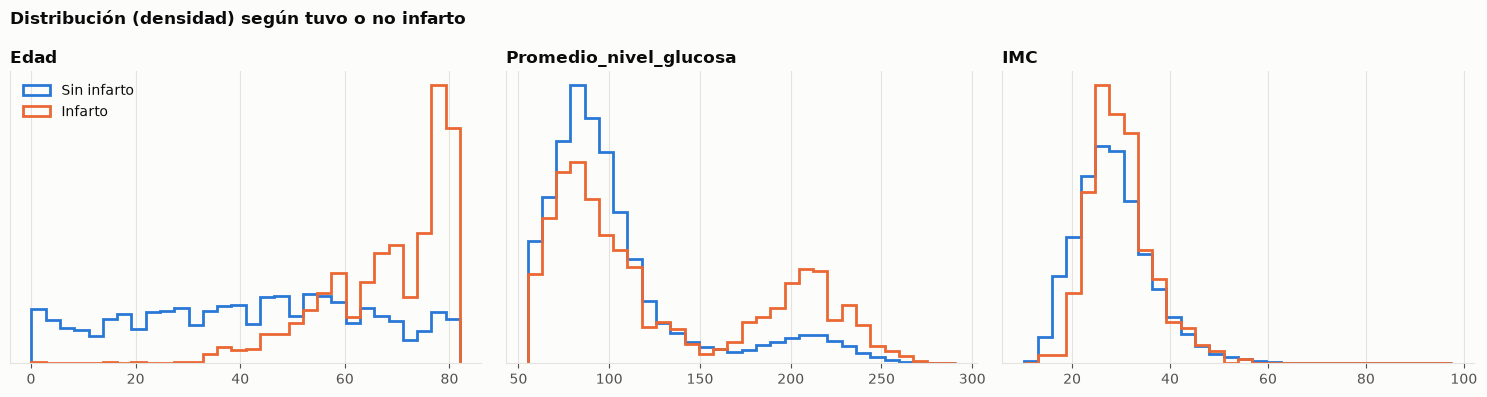

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['Edad', 'Promedio_nivel_glucosa', 'IMC']):
    datos = df[[col, TARGET]].dropna()
    bins = np.histogram_bin_edges(datos[col], bins=30)
    ax.hist(datos.loc[datos[TARGET] == 0, col], bins=bins, density=True,
            histtype='step', linewidth=2, color=G.SERIE_1, label='Sin infarto')
    ax.hist(datos.loc[datos[TARGET] == 1, col], bins=bins, density=True,
            histtype='step', linewidth=2, color=G.SERIE_2, label='Infarto')
    ax.set_title(col, loc='left')
    ax.set_yticks([])
    ax.grid(True, axis='x')
axes[0].legend(frameon=False)
fig.suptitle('Distribución (densidad) según tuvo o no infarto', x=0.01, ha='left',
             fontweight='bold')
plt.tight_layout()
plt.show()

In [7]:
df[['Edad', 'Promedio_nivel_glucosa', 'IMC', 'Flag_hipertension',
    'Flag_problem_cardiaco', TARGET]].corr()[[TARGET]].sort_values(TARGET, ascending=False)

,Ataque_cardiaco
Ataque_cardiaco,1.000
Edad,0.156
Flag_problem_cardiaco,0.114
Promedio_nivel_glucosa,0.079
Flag_hipertension,0.075
IMC,0.020


La **edad** es la variable que más separa: casi todos los infartos ocurren después de los 45.
La **glucosa** alta y los antecedentes de **hipertensión** y **problema cardiaco** también suben el riesgo.
El IMC aporta poco por sí solo.

## 3. Variables cualitativas: tasa de infarto por categoría

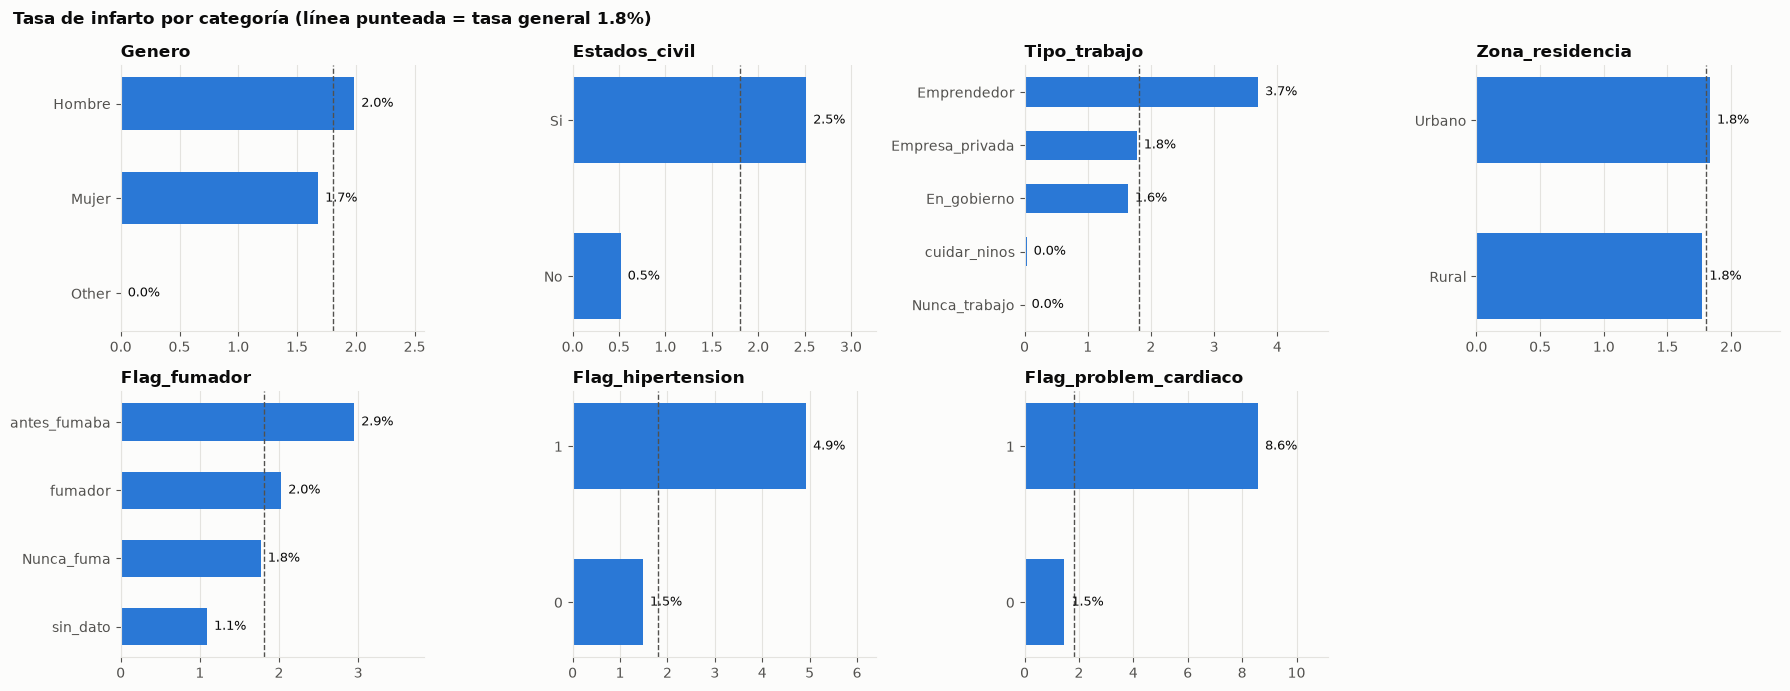

In [8]:
def grafico_tasa(ax, data, col, ordinal=False):
    """Tasa de infarto por categoría (barras horizontales) vs la tasa general."""
    t = data.groupby(col)[TARGET].mean()
    t = t.sort_index(ascending=False) if ordinal else t.sort_values()
    ax.barh(t.index.astype(str), t.values * 100, color=G.SERIE_1, height=0.55)
    for i, v in enumerate(t.values * 100):
        ax.text(v + t.max() * 100 * 0.03, i, f'{v:.1f}%', va='center', fontsize=9, color=G.TEXTO)
    ax.axvline(tasa * 100, color=G.TEXTO_SEC, linestyle='--', linewidth=1)
    ax.set_title(col, loc='left')
    ax.set_xlim(0, t.max() * 100 * 1.3)
    ax.grid(True, axis='x')
    ax.set_axisbelow(True)


cualitativas = ['Genero', 'Estados_civil', 'Tipo_trabajo', 'Zona_residencia',
                'Flag_fumador', 'Flag_hipertension', 'Flag_problem_cardiaco']
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, col in zip(axes.flat, cualitativas):
    grafico_tasa(ax, df.fillna({'Flag_fumador': 'sin_dato'}), col)
axes.flat[-1].set_visible(False)
fig.suptitle(f'Tasa de infarto por categoría (línea punteada = tasa general {tasa:.1%})',
             x=0.01, ha='left', fontweight='bold')
plt.tight_layout()
plt.show()

**Conclusiones de variables** (mismas del notebook del caso):

- Numéricas importantes: Edad, Flag_problem_cardiaco, Promedio_nivel_glucosa, Flag_hipertension, IMC.
- Cualitativas importantes: Estados_civil y Tipo_trabajo. Su efecto está muy ligado a la edad:
  quienes alguna vez se casaron o trabajan por cuenta propia son, en promedio, mayores.
- Genero y Zona_residencia casi no cambian la tasa. Flag_fumador tiene 31% de vacíos.

## 4. Tratamiento de IMC y transformación de variables

In [9]:
imc_avg, imc_std = df['IMC'].mean(), df['IMC'].std()
df_t = imputar_imc(df, imc_avg, imc_std, seed=123)
df_t = transformar_variables(df_t)
print(f'IMC imputado con valores uniformes en [{imc_avg - imc_std:.1f}, {imc_avg + imc_std:.1f}]')
df_t[FEATURES + [TARGET]].head()

IMC imputado con valores uniformes en [20.8, 36.4]


,Flag_hipertension,Flag_problem_cardiaco,Edad_Encoded,Gluocosa_Encoded,IMC_Encoded,Estado_Encoded,TipoTrabajo_Encoded,Ataque_cardiaco
0,0,0,1,1,1,2,4,0
1,1,0,5,1,4,1,2,0
2,0,0,2,2,1,2,2,0
3,0,0,6,1,4,1,2,0
4,0,0,4,3,2,2,4,0


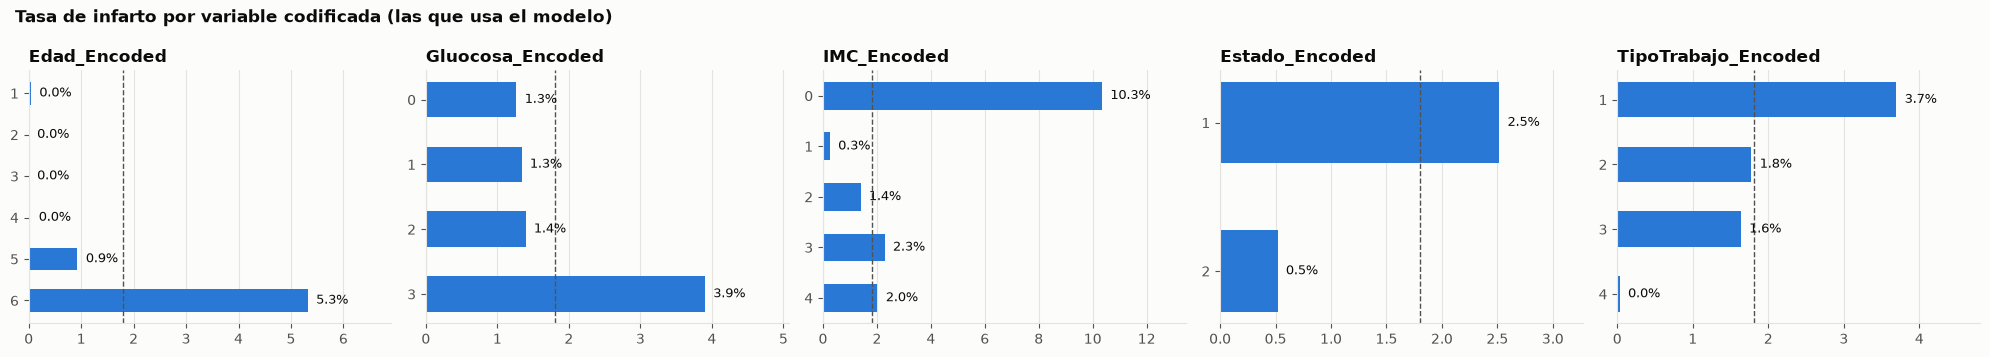

In [10]:
codificadas = ['Edad_Encoded', 'Gluocosa_Encoded', 'IMC_Encoded',
               'Estado_Encoded', 'TipoTrabajo_Encoded']
fig, axes = plt.subplots(1, 5, figsize=(20, 3.6))
for ax, col in zip(axes, codificadas):
    grafico_tasa(ax, df_t, col, ordinal=True)
fig.suptitle('Tasa de infarto por variable codificada (las que usa el modelo)',
             x=0.01, ha='left', fontweight='bold')
plt.tight_layout()
plt.show()

Las variables codificadas conservan la señal: el riesgo sube de forma clara con
`Edad_Encoded` (6 = 60 años o más) y con `Gluocosa_Encoded` (3 = rango de diabetes).
El 10% de `IMC_Encoded = 0` no es una señal: son solo 29 asegurados que caen en los huecos
de los cortes del notebook (IMC entre 24.9 y 25, o entre 29.9 y 30).
Estas son las 7 variables que entran al modelo; la API aplica la misma función
`transformar_variables()` a cada paciente.

## 5. ¿Qué técnica de balanceo usar?

In [11]:
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

X, y = df_t[FEATURES], df_t[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=123, stratify=y)

filas = []
for tecnica in ['original', 'undersampling', 'oversampling', 'smote']:
    if tecnica == 'original':
        Xb, yb = X_train, y_train
    else:
        Xb, yb = obtener_balanceador(tecnica, 123).fit_resample(X_train, y_train)
    pred = DecisionTreeClassifier(random_state=123).fit(Xb, yb).predict(X_test)
    filas.append({'Balanceo': tecnica, 'Filas train': len(yb),
                  'Recall': recall_score(y_test, pred),
                  'Precision': precision_score(y_test, pred, zero_division=0),
                  'F1': f1_score(y_test, pred)})
pd.DataFrame(filas).set_index('Balanceo')

,Filas train,Recall,Precision,F1
Balanceo,,,,
original,34720,0.000,0.000,0.000
undersampling,1252,0.777,0.051,0.095
oversampling,68188,0.732,0.047,0.088
smote,68188,0.694,0.045,0.085


Sin balanceo el árbol no detecta ningún infarto (recall 0). Las tres técnicas suben el recall
a ~0.7; **undersampling** lo logra entrenando con muchas menos filas, por eso el caso la elige.
En el pipeline el balanceo va dentro de un `Pipeline` de imblearn para que solo afecte a los
folds de entrenamiento de la validación cruzada.

La precisión queda baja (~5%) por construcción: con 1.8% de positivos, por cada infarto
detectado se incluyen varios asegurados sanos en el programa. Para la aseguradora es un buen
trato, porque un falso positivo cuesta un chequeo preventivo y un falso negativo, un infarto
no atendido (ver `config.yaml → negocio`).

## 6. Del notebook al pipeline

| Paso del notebook | Dónde quedó en el proyecto |
|---|---|
| Cargar datos | `data/run.py` → `src/data_loader.cargar_datos()` |
| Tratamiento de IMC | `preprocess/run.py` → `src/preprocessing.imputar_imc()` |
| Transformar variables | `src/preprocessing.transformar_variables()` (pipeline **y** API) |
| Train/test split | `segregate/run.py` (estratificado) |
| Balanceo + Random Forest tuneado | `random_forest/run.py` (GridSearchCV + RandomizedSearchCV + MLflow) |
| Evaluación | `evaluate/run.py` (quality gate AUC/Recall/F1 + Model Registry) |
| Predicción con nuevos datos | `api/` → `POST /predecir` |

Ejecutar todo el pipeline: `python main.py`